# Personal Information
Name: Sharanda Suttorp

StudentID: 15841545

Email: [**sharanda.suttorp@student.uva.nl**](sharanda.suttorp@student.uva.nl)

Submitted on: **18.03.2026**

# Data Context

This notebook explores the **Anti-UAV** dataset ([link to paper](https://arxiv.org/abs/2101.08466)) for UAV tracking in RGB and thermal video sequences. The data is organised by split (train/validation/test), with each sequence containing paired (but not aligned) visible (RGB) and infrared (thermal) annotations. Per-frame labels include target presence (*exist*: 0/1), bounding boxes (*gt_rect*: [x, y, w, h]), and sequence-level attributes (FM, SV, LR, LI, OV, OC, TC-EASY/MID/HARD) that describe challenge types. The EDA supports understanding dataset structure, target and box statistics, attribute usage, and RGB vs thermal behaviour before modelling.

# Data Description

The following sections are included in the EDA plan:

1. **Dataset structure**: Sequences, frames, train/val/test split
2. **Target analysis**: Presence/absence (exist), absence segments
3. **Bounding box analysis**: Width, height, area, aspect ratio, position heatmap, scale
4. **Attribute analysis**: Attribute frequency, co-occurrence, frequent attribute combinations
5. **RGB vs thermal**: Cross-modal alignment and modality-degradation
6. **Data cleaning**: exist vs bbox consistency, invalid/zero-area boxes
7. **Conclusion**: conclusions of the 6 sections above

## Imports

In [29]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

## Data Loading

Paths: annotations per sequence in `{split}/{seq_id}/visible.json` and `infrared.json` (keys: `exist`, `gt_rect`). Attribute labels in `label_new/{train,val,test}.json` (sequence_id -> list of attributes).

In [9]:
# Base path to Anti-UAV-RGBT
DATA_ROOT = Path("C:/Users/shara/Documents/MasterIS/thesis/Anti-UAV-RGBT")
LABEL_DIR = DATA_ROOT / "label_new"
SPLITS = ["train", "val", "test"]
MODALITIES = ["visible", "infrared"]

def load_sequence_anno(split: str, seq_id: str, modality: str) -> dict:
    """Load one sequence annotation (exist + gt_rect) for a given modality."""
    path = DATA_ROOT / split / seq_id / f"{modality}.json"
    if not path.exists():
        return None
    with open(path, "r") as f:
        return json.load(f)

def load_attribute_labels() -> dict:
    """Load sequence_id -> list of attributes for each split."""
    out = {}
    for split in SPLITS:
        path = LABEL_DIR / f"{split}.json"
        if path.exists():
            with open(path, "r") as f:
                out[split] = json.load(f)
    return out

# Discover sequences per split (from folder names)
def get_sequence_ids() -> dict:
    ids = {}
    for split in SPLITS:
        split_path = DATA_ROOT / split
        if split_path.exists():
            ids[split] = [d.name for d in split_path.iterdir() if d.is_dir()]
    return ids

seq_ids = get_sequence_ids()
attr_labels = load_attribute_labels()
print("Sequences per split:", {k: len(v) for k, v in seq_ids.items()})
print("Attribute keys (train):", list(attr_labels.get("train", {}).keys())[:3], "...")
print("Attribute values (train):", list(attr_labels.get("train", {}).values())[:3], "...")

Sequences per split: {'train': 160, 'val': 67, 'test': 91}
Attribute keys (train): ['20190925_101846_1_1', '20190925_101846_1_2', '20190925_101846_1_3'] ...
Attribute values (train): [['FM', 'SV', 'OV'], ['SV', 'TC', 'TC-EASY'], ['FM', 'SV', 'LR', 'TC', 'TC-EASY']] ...


### Build unified annotation table

Build a dataframe: one row per (split, seq_id, modality, frame_idx) with exist, bbox, and sequence attributes for easier analysis.

In [10]:
def is_valid_bbox(bbox) -> bool:
    """Check if bbox is non-empty and has positive area. bbox: [x,y,w,h] or [] or [0,0,0,0]."""
    if not bbox or len(bbox) != 4:
        return False
    x, y, w, h = bbox
    return float(w) > 0 and float(h) > 0

def flatten_annotations(seq_ids_dict, attr_labels_dict):
    """Flatten to rows: split, seq_id, modality, frame_idx, exist, w, h, area, aspect_ratio, attributes."""
    rows = []
    for split, ids in seq_ids_dict.items():
        attrs = attr_labels_dict.get(split, {})
        for seq_id in ids:
            seq_attrs = attrs.get(seq_id, [])
            for mod in MODALITIES:
                anno = load_sequence_anno(split, seq_id, mod)
                if anno is None:
                    continue
                exist_list = anno.get("exist", [])
                gt_rect = anno.get("gt_rect", [])
                n = len(exist_list)
                for i in range(n):
                    ex = exist_list[i] if i < len(exist_list) else 0
                    rect = gt_rect[i] if i < len(gt_rect) else []
                    x = y = w = h = area = aspect = np.nan
                    if is_valid_bbox(rect):
                        x, y, w, h = rect
                        area = w * h
                        aspect = w / h if h else np.nan
                    rows.append({
                        "split": split, "seq_id": seq_id, "modality": mod, "frame_idx": i,
                        "exist": ex, "x": x, "y": y, "w": w, "h": h, "area": area, "aspect_ratio": aspect,
                        "attributes": seq_attrs
                    })
    return pd.DataFrame(rows)

df = flatten_annotations(seq_ids, attr_labels)
print(df.shape)

# Measured from dataset videos: visible=1920x1080, infrared=640x512
FRAME_SIZE_BY_MODALITY = {
    "visible": (1920, 1080),
    "infrared": (640, 512),
}
df["frame_w"] = df["modality"].map(lambda m: FRAME_SIZE_BY_MODALITY[m][0])
df["frame_h"] = df["modality"].map(lambda m: FRAME_SIZE_BY_MODALITY[m][1])

(593802, 12)


In [11]:
df.head(10)

,split,seq_id,modality,frame_idx,exist,x,y,w,h,area,aspect_ratio,attributes,frame_w,frame_h
0,train,20190925_101846_1_1,visible,0,1,664.0,542.0,211.0,122.0,25742.0,1.729508,"[FM, SV, OV]",1920,1080
1,train,20190925_101846_1_1,visible,1,1,663.0,542.0,211.0,121.0,25531.0,1.743802,"[FM, SV, OV]",1920,1080
2,train,20190925_101846_1_1,visible,2,1,663.0,542.0,212.0,121.0,25652.0,1.752066,"[FM, SV, OV]",1920,1080
3,train,20190925_101846_1_1,visible,3,1,663.0,542.0,212.0,121.0,25652.0,1.752066,"[FM, SV, OV]",1920,1080
4,train,20190925_101846_1_1,visible,4,1,662.0,542.0,213.0,120.0,25560.0,1.775000,"[FM, SV, OV]",1920,1080
5,train,20190925_101846_1_1,visible,5,1,662.0,542.0,213.0,120.0,25560.0,1.775000,"[FM, SV, OV]",1920,1080
6,train,20190925_101846_1_1,visible,6,1,662.0,542.0,214.0,120.0,25680.0,1.783333,"[FM, SV, OV]",1920,1080
7,train,20190925_101846_1_1,visible,7,1,661.0,542.0,215.0,119.0,25585.0,1.806723,"[FM, SV, OV]",1920,1080
8,train,20190925_101846_1_1,visible,8,1,661.0,542.0,215.0,119.0,25585.0,1.806723,"[FM, SV, OV]",1920,1080
9,train,20190925_101846_1_1,visible,9,1,660.0,542.0,216.0,118.0,25488.0,1.830508,"[FM, SV, OV]",1920,1080


---
## 1. Dataset structure

- Number of sequences (videos) and frames
- Frames per sequence (distribution)
- Train/validation/test split verification

In [12]:
# Sequences and total frames per split: visible modality
structure = []
for split in SPLITS:
    for seq_id in seq_ids.get(split, []):
        anno = load_sequence_anno(split, seq_id, "visible")
        if anno:
            n_frames = len(anno.get("exist", []))
            structure.append({"split": split, "seq_id": seq_id, "n_frames": n_frames})
struct_df = pd.DataFrame(structure)

print("Visible modality")
print("Number of sequences and total frames per split:")
summary = struct_df.groupby("split").agg(
    n_sequences=("seq_id", "count"),
    total_frames=("n_frames", "sum"),
    mean_frames=("n_frames", "mean"),
    min_frames=("n_frames", "min"),
    max_frames=("n_frames", "max")
).round(1)
print(summary)
print("\nTotal sequences:", struct_df["seq_id"].nunique())
print("Total frames (visible):", struct_df["n_frames"].sum())

# Sequences and total frames per split: infrared modality
structure = []
for split in SPLITS:
    for seq_id in seq_ids.get(split, []):
        anno = load_sequence_anno(split, seq_id, "infrared")
        if anno:
            n_frames = len(anno.get("exist", []))
            structure.append({"split": split, "seq_id": seq_id, "n_frames": n_frames})
struct_df = pd.DataFrame(structure)

print("\n")
print("Infrared modality")
print("Number of sequences and total frames per split:")
summary = struct_df.groupby("split").agg(
    n_sequences=("seq_id", "count"),
    total_frames=("n_frames", "sum"),
    mean_frames=("n_frames", "mean"),
    min_frames=("n_frames", "min"),
    max_frames=("n_frames", "max")
).round(1)
print(summary)
print("\nTotal sequences:", struct_df["seq_id"].nunique())
print("Total frames (infrared):", struct_df["n_frames"].sum())

Visible modality
Number of sequences and total frames per split:
       n_sequences  total_frames  mean_frames  min_frames  max_frames
split                                                                
test            91         85374        938.2         139        1000
train          160        149528        934.6          28        1000
val             67         61999        925.4          39        1000

Total sequences: 318
Total frames (visible): 296901


Infrared modality
Number of sequences and total frames per split:
       n_sequences  total_frames  mean_frames  min_frames  max_frames
split                                                                
test            91         85374        938.2         139        1000
train          160        149528        934.6          28        1000
val             67         61999        925.4          39        1000

Total sequences: 318
Total frames (infrared): 296901


The dataset is split roughly 50/21/29% across train/val/test by sequence count, with all splits showing near-identical mean sequence lengths (~930–940 frames). The consistent lengths indicate uniform data collection. The minimum of 28 frames (train) is an outlier. These very short sequences contribute negligible data volume and are unlikely to affect training.

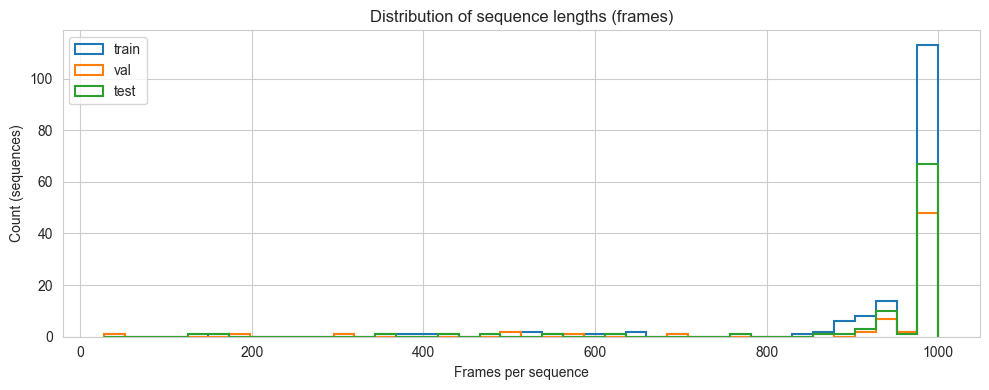

In [13]:
# Distribution of frames per sequence
all_n_frames = struct_df["n_frames"]
shared_bins = np.linspace(all_n_frames.min(), all_n_frames.max(), 41)

fig, ax = plt.subplots(figsize=(10, 4))
for split in SPLITS:
    s = struct_df[struct_df["split"] == split]["n_frames"]
    ax.hist(s, bins=shared_bins, histtype="step", linewidth=1.5, label=split)
ax.set_xlabel("Frames per sequence")
ax.set_ylabel("Count (sequences)")
ax.legend()
ax.set_title("Distribution of sequence lengths (frames)")
plt.tight_layout()
plt.show()

Sequence lengths cluster near 1000 frames with a small tail of short sequences. The uniform distribution across splits indicates consistent division. The few short sequences (<200 frames) are too rare to significantly bias training or evaluation.


---
## 2. Target analysis

Using the per-frame *exist* label (0 = UAV absent, 1 = UAV present):

- Frame-level class balance: fraction of present/absent frames per split and modality
- Per-sequence visibility fraction: how consistently the drone is visible within each sequence
- Absence & presence segment lengths: how long the drone stays visible or disappears in one stretch
- Appearance events per sequence: number of times the drone re-enters the frame (0→1 transitions)

In [14]:
# helper
def run_lengths(seq, value):
    """Lengths of contiguous runs of `value` in seq."""
    lengths, run = [], 0
    for v in seq:
        if v == value:
            run += 1
        else:
            if run > 0:
                lengths.append(run)
            run = 0
    if run > 0:
        lengths.append(run)
    return lengths

In [15]:
# 1. Frame-level class balance
# how imbalanced is each split/modality?
balance = (
    df.groupby(["split", "modality"])["exist"]
    .agg(n_frames="count", n_present="sum")
    .assign(present_percentage=lambda x: x["n_present"] / x["n_frames"] * 100)
    .round(2)
)
print("Frame-level UAV visibility (class balance) per split & modality:")
print(balance)

Frame-level UAV visibility (class balance) per split & modality:
                n_frames  n_present  present_percentage
split modality                                         
test  infrared     85374      84221               98.65
      visible      85374      79724               93.38
train infrared    149528     148368               99.22
      visible     149528     142192               95.09
val   infrared     61999      60620               97.78
      visible      61999      58302               94.04


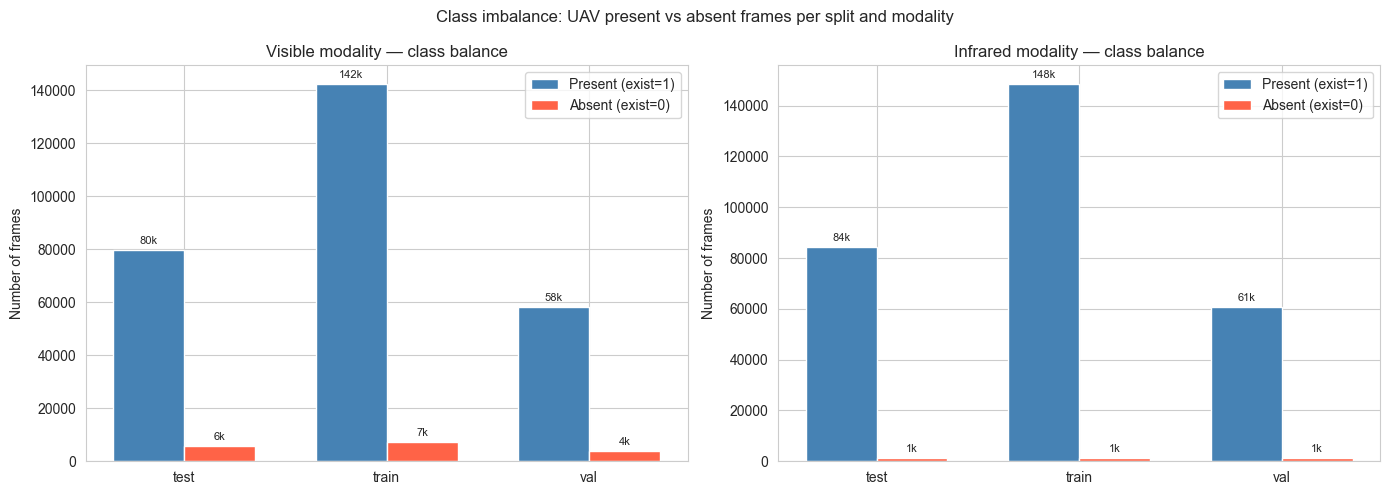

Imbalance ratio (present:absent) per split & modality:
split modality  n_present  n_absent  present_percentage  ratio_present_to_absent
 test infrared      84221      1153               98.65                     73.0
 test  visible      79724      5650               93.38                     14.1
train infrared     148368      1160               99.22                    127.9
train  visible     142192      7336               95.09                     19.4
  val infrared      60620      1379               97.78                     44.0
  val  visible      58302      3697               94.04                     15.8


In [16]:
# Visualize class imbalance: present vs absent frames per split and modality
balance_reset = balance.reset_index()
balance_reset["n_absent"] = balance_reset["n_frames"] - balance_reset["n_present"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, modality in zip(axes, ["visible", "infrared"]):
    sub = balance_reset[balance_reset["modality"] == modality]
    x = np.arange(len(sub))
    width = 0.35
    bars1 = ax.bar(x - width/2, sub["n_present"], width, label="Present (exist=1)", color="steelblue")
    bars2 = ax.bar(x + width/2, sub["n_absent"],  width, label="Absent (exist=0)",  color="tomato")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["split"].values)
    ax.set_title(f"{modality.capitalize()} modality — class balance")
    ax.set_ylabel("Number of frames")
    ax.legend()
    ax.bar_label(bars1, labels=[f"{v/1000:.0f}k" for v in sub["n_present"]], padding=3, fontsize=8)
    ax.bar_label(bars2, labels=[f"{v/1000:.0f}k" for v in sub["n_absent"]],  padding=3, fontsize=8)

plt.suptitle("Class imbalance: UAV present vs absent frames per split and modality")
plt.tight_layout()
plt.show()

balance_reset["ratio_present_to_absent"] = (
    balance_reset["n_present"] / (balance_reset["n_frames"] - balance_reset["n_present"])
).round(1)
print("Imbalance ratio (present:absent) per split & modality:")
print(balance_reset[["split", "modality", "n_present", "n_absent",
                      "present_percentage", "ratio_present_to_absent"]].to_string(index=False))


In [ ]:
# Naive baseline: always predict exist=1
# Shows why accuracy is misleading given class imbalance
import sklearn
from sklearn.metrics import precision_score, recall_score, f1_score

print("Naive 'always predict present' baseline metrics:\n")
for split in SPLITS:
    for mod in MODALITIES:
        y_true = df[(df["split"] == split) & (df["modality"] == mod)]["exist"].values
        y_pred = np.ones_like(y_true)  # always predict 1
        acc  = y_true.mean()           # = % present
        prec = precision_score(y_true, y_pred)
        rec  = recall_score(y_true, y_pred)
        f1   = f1_score(y_true, y_pred)
        print(f"  {split} / {mod}: accuracy={acc:.3f}, precision={prec:.3f}, recall={rec:.3f}, F1={f1:.3f}")


Naive 'always predict present' baseline metrics:

  train / visible: accuracy=0.951, precision=0.951, recall=1.000, F1=0.975
  train / infrared: accuracy=0.992, precision=0.992, recall=1.000, F1=0.996
  val / visible: accuracy=0.940, precision=0.940, recall=1.000, F1=0.969
  val / infrared: accuracy=0.978, precision=0.978, recall=1.000, F1=0.989
  test / visible: accuracy=0.934, precision=0.934, recall=1.000, F1=0.966
  test / infrared: accuracy=0.986, precision=0.986, recall=1.000, F1=0.993


### Model evaluation implications of class imbalance

The >93% presence rate (visible) and >98% (infrared) makes accuracy a misleading metric.
A model predicting "always present" would score >93% while providing no threat-detection value.

The critical failure mode is a **false negative**: missing a real drone. Evaluation should prioritise:

- **Recall**: Fraction of real presence frames detected. A missed UAV is the highest-risk failure.  
- **Precision**: Fraction of "present" predictions that are correct. Low precision means many false alarms.  
- **F1-score**: Harmonic mean of precision and recall.  
- **AUC-ROC**: Measures discrimination across all thresholds and is more robust to class imbalance.

We will report results using per class metrics (exist=0 and exist=1). A real model must demonstrate strong perofrmance specifically on the absent class (exist=0).


In [17]:
# 2. Per-sequence visibility fraction
# are most sequences fully visible, fully absent, or mixed?
seq_vis = (
    df.groupby(["split", "seq_id", "modality"])["exist"]
    .mean()
    .rename("frac_visible")
    .reset_index()
)
print("\nPer-sequence visibility fraction stats (by split & modality):")
print(seq_vis.groupby(["split", "modality"])["frac_visible"]
      .agg(["mean", "std", "min", "max"]).round(3))


Per-sequence visibility fraction stats (by split & modality):
                 mean    std    min  max
split modality                          
test  infrared  0.983  0.072  0.376  1.0
      visible   0.933  0.155  0.162  1.0
train infrared  0.991  0.039  0.662  1.0
      visible   0.952  0.116  0.351  1.0
val   infrared  0.979  0.114  0.077  1.0
      visible   0.944  0.168  0.072  1.0


The mean visibility fraction exceeds 0.93 (visible) and 0.97 (infrared) across all splits, meaning the drone is present for nearly the entire duration of most sequences.

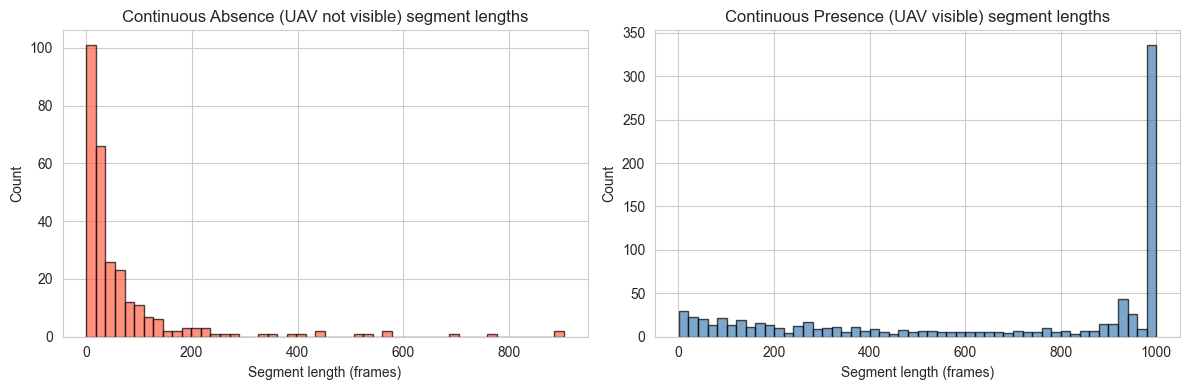

Absence segment lengths:
count    282.00
mean      72.25
std      128.97
min        1.00
25%       14.00
50%       28.00
75%       70.00
max      903.00
dtype: float64

Presence segment lengths:
count     865.00
mean      662.92
std       376.36
min         1.00
25%       274.00
50%       899.00
75%      1000.00
max      1000.00
dtype: float64


In [18]:
# 3. Absence & presence segment lengths
# how long does the UAV disappear?
# how long does it stay visible?
abs_lengths, pres_lengths = [], []
for (split, seq_id, mod), g in df.groupby(["split", "seq_id", "modality"]):
    ex = g.sort_values("frame_idx")["exist"].tolist()
    abs_lengths.extend(run_lengths(ex, 0))
    pres_lengths.extend(run_lengths(ex, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lengths, label, color in zip(
    axes,
    [abs_lengths, pres_lengths],
    ["Absence (UAV not visible)", "Presence (UAV visible)"],
    ["tomato", "steelblue"],
):
    ax.hist(lengths, bins=50, edgecolor="black", alpha=0.7, color=color)
    ax.set_xlabel("Segment length (frames)")
    ax.set_ylabel("Count")
    ax.set_title(f"Continuous {label} segment lengths")
plt.tight_layout()
plt.show()

print("Absence segment lengths:")
print(pd.Series(abs_lengths).describe().round(2))
print("\nPresence segment lengths:")
print(pd.Series(pres_lengths).describe().round(2))

Absence segments are almost always short (typically a few frames), meaning disappearances are brief. Presence segments are long and uninterrupted, confirming that continuous tracking is the dominant pattern.


Appearance events per sequence (by split & modality):
                mean   std  max  median
split modality                         
test  infrared  1.43  1.07    6     1.0
      visible   1.59  0.92    5     1.0
train infrared  1.21  0.82    8     1.0
      visible   1.45  1.01    7     1.0
val   infrared  1.13  0.39    3     1.0
      visible   1.31  0.61    4     1.0


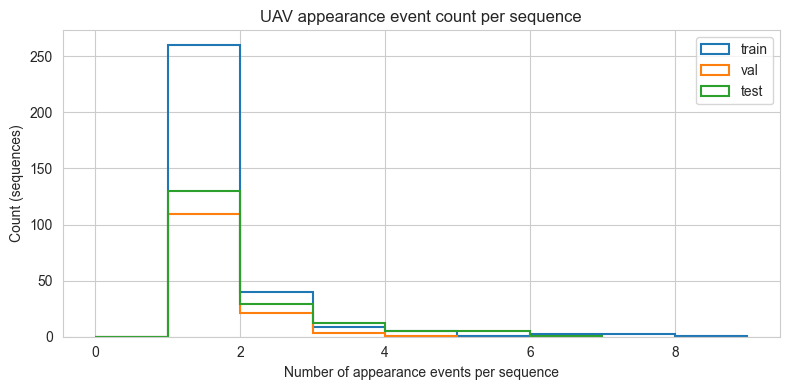

In [19]:
# 4. Appearance events per sequence
# how many times does the UAV appear/disappear per sequence?
# high count = tracker must re-identify many times = harder task.
def count_appearances(exist_list):
    """Number of 0→1 transitions (= number of separate presence segments)."""
    return sum(
        1 for i in range(1, len(exist_list))
        if exist_list[i] == 1 and exist_list[i - 1] == 0
    ) + (1 if exist_list and exist_list[0] == 1 else 0)

app_records = []
for (split, seq_id, mod), g in df.groupby(["split", "seq_id", "modality"]):
    ex = g.sort_values("frame_idx")["exist"].tolist()
    app_records.append({"split": split, "seq_id": seq_id, "modality": mod,
                        "n_appearances": count_appearances(ex)})
app_df = pd.DataFrame(app_records)

print("\nAppearance events per sequence (by split & modality):")
print(app_df.groupby(["split", "modality"])["n_appearances"]
      .agg(["mean", "std", "max", "median"]).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for split in SPLITS:
    vals = app_df[app_df["split"] == split]["n_appearances"]
    ax.hist(vals, bins=range(0, vals.max() + 2), histtype="step",
            linewidth=1.5, label=split)
ax.set_xlabel("Number of appearance events per sequence")
ax.set_ylabel("Count (sequences)")
ax.set_title("UAV appearance event count per sequence")
ax.legend()
plt.tight_layout()
plt.show()

Most sequences contain only 1–2 appearance events, meaning the drone is typically acquired once and tracked without interruption. Sequences with many events (>5) represent hard cases requiring repeated re-identification.

---
## 3. Bounding box analysis

Using [x, y, w, h]: 
- width, height, area distribution
- aspect ratio distribution
- position heatmaps
- scale distribution

Frames with valid bbox: 572982 / 593802 (96.49% of all frames)
Among exist=1 frames: 572982 / 573427 (99.92%)


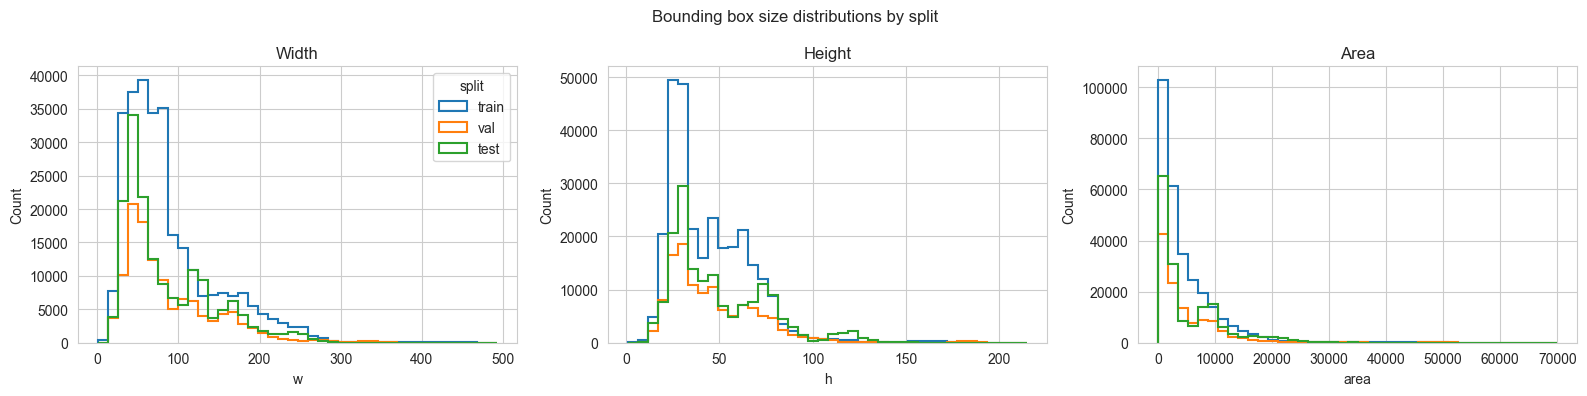

In [20]:
# Restrict to frames with valid bbox (exist=1 and valid box)
df_bbox = df[(df["exist"] == 1) & (df["w"].notna()) & (df["w"] > 0)].copy()
n_valid_bbox = len(df_bbox)
n_total = len(df)
n_exist1 = int((df["exist"] == 1).sum())
print(f"Frames with valid bbox: {n_valid_bbox} / {n_total} ({100*n_valid_bbox/n_total:.2f}% of all frames)")
print(f"Among exist=1 frames: {n_valid_bbox} / {n_exist1} ({100*n_valid_bbox/n_exist1:.2f}%)")

# Width, height, area distributions by split
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["w", "h", "area"], ["Width", "Height", "Area"]):
    all_vals = df_bbox[col].dropna()
    shared_bins = np.linspace(all_vals.min(), all_vals.max(), 41)
    for split in SPLITS:
        s = df_bbox[df_bbox["split"] == split][col].dropna()
        ax.hist(s, bins=shared_bins, histtype="step", linewidth=1.5, label=split)
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
axes[0].legend(title="split")
plt.suptitle("Bounding box size distributions by split")
plt.tight_layout()
plt.show()

Bounding box widths, heights, and areas are right-skewed, with the majority of detections involving small boxes. This confirms a small-object detection task. The long tail of large boxes reflects close-range frames.

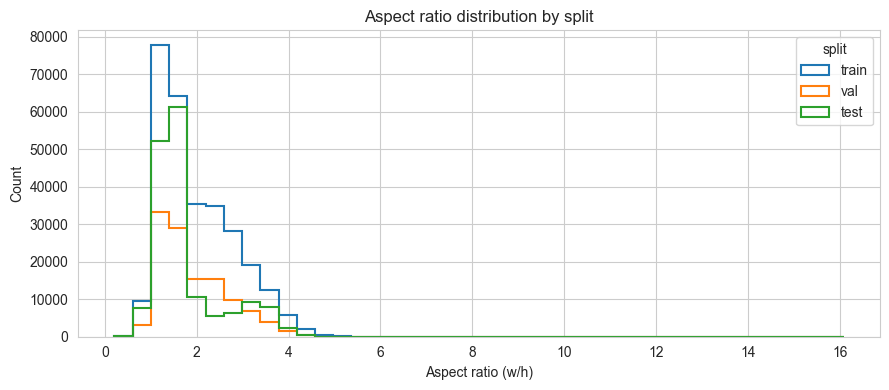

In [21]:
# Aspect ratio (w/h) distribution by split
all_aspect = df_bbox["aspect_ratio"].dropna()
shared_bins = np.linspace(all_aspect.min(), all_aspect.max(), 41)

plt.figure(figsize=(9, 4))
for split in SPLITS:
    s = df_bbox[df_bbox["split"] == split]["aspect_ratio"].dropna()
    plt.hist(s, bins=shared_bins, histtype="step", linewidth=1.5, label=split)
plt.xlabel("Aspect ratio (w/h)")
plt.ylabel("Count")
plt.title("Aspect ratio distribution by split")
plt.legend(title="split")
plt.tight_layout()
plt.show()

The aspect ratio distribution is concentrated around 1, indicating that UAV bounding boxes are roughly square. Therefore, only one or two square anchors are sufficient to cover most targets.

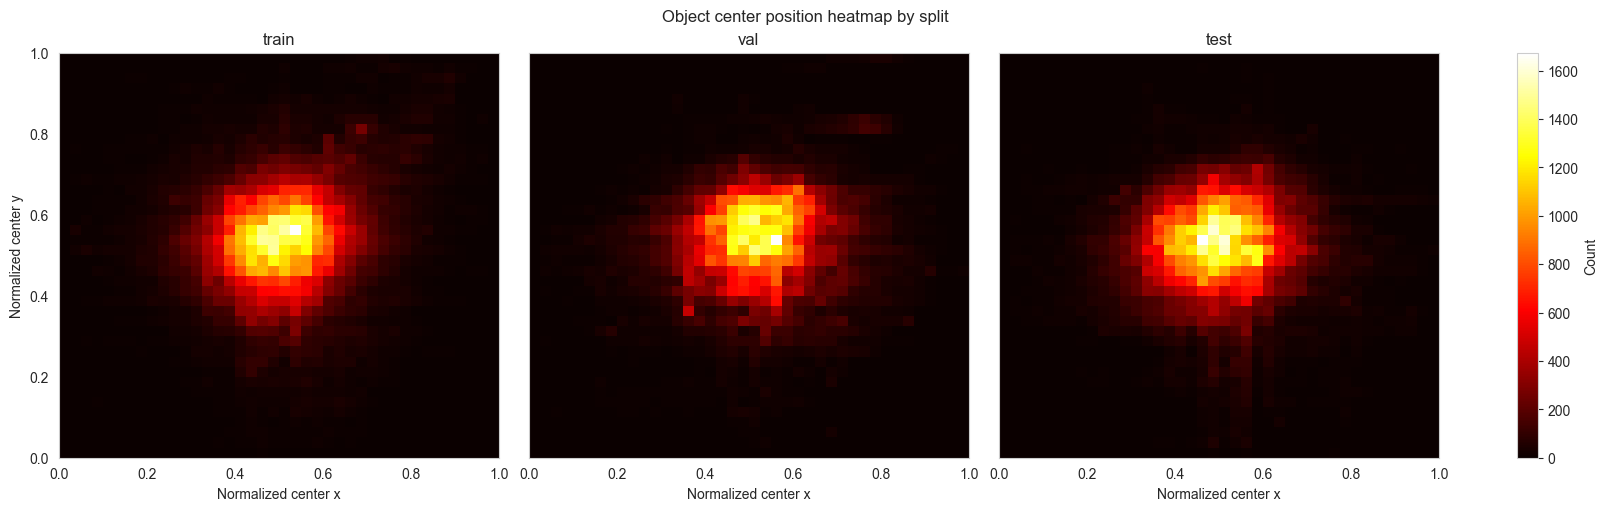

In [22]:
# Object center position heatmap normalized by each frame size (cx_norm, cy_norm in [0,1])
df_bbox["cx"] = df_bbox["x"] + df_bbox["w"] / 2
df_bbox["cy"] = df_bbox["y"] + df_bbox["h"] / 2
df_bbox["cx_norm"] = df_bbox["cx"] / df_bbox["frame_w"]
df_bbox["cy_norm"] = df_bbox["cy"] / df_bbox["frame_h"]

if len(df_bbox) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True, constrained_layout=True)
    for ax, split in zip(axes, ["train", "val", "test"]):
        s = df_bbox[df_bbox["split"] == split]
        h = ax.hist2d(s["cx_norm"], s["cy_norm"], bins=40, range=[[0, 1], [0, 1]], cmap="hot")
        ax.set_title(split)
        ax.set_xlabel("Normalized center x")
    axes[0].set_ylabel("Normalized center y")
    fig.colorbar(h[3], ax=axes, label="Count")
    plt.suptitle("Object center position heatmap by split")
    plt.show()

Drone positions are strongly concentrated near the frame center across all splits, reflecting how the rotating turret film by keeping the target in view. This spatial bias risks the model learning position priors rather than appearance features, which would hurt performance on off-center targets.

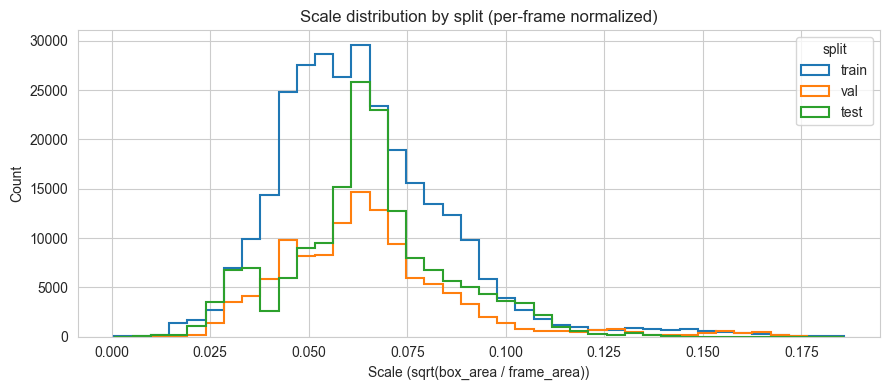

          count    mean     std     min     25%     50%     75%     max
split                                                                  
test   163877.0  0.0652  0.0201  0.0030  0.0541  0.0646  0.0749  0.1525
train  290295.0  0.0636  0.0219  0.0007  0.0489  0.0609  0.0751  0.1857
val    118810.0  0.0651  0.0232  0.0039  0.0496  0.0629  0.0743  0.1818


In [23]:
# Scale distribution normalized by each frame's own area, shown by split
if len(df_bbox) > 0 and "area" in df_bbox.columns:
    frame_area = df_bbox["frame_w"] * df_bbox["frame_h"]
    df_bbox["scale"] = np.sqrt(df_bbox["area"] / frame_area)

    all_scale = df_bbox["scale"].dropna()
    shared_bins = np.linspace(all_scale.min(), all_scale.max(), 41)

    plt.figure(figsize=(9, 4))
    for split in SPLITS:
        s = df_bbox[df_bbox["split"] == split]["scale"].dropna()
        plt.hist(s, bins=shared_bins, histtype="step", linewidth=1.5, label=split)
    plt.xlabel("Scale (sqrt(box_area / frame_area))")
    plt.ylabel("Count")
    plt.title("Scale distribution by split (per-frame normalized)")
    plt.legend(title="split")
    plt.tight_layout()
    plt.show()

    print(df_bbox.groupby("split")["scale"].describe().round(4))

The normalized scale (sqrt(box area / frame area)) is consistently small across both modalities, with most values below 0.1. This quantifies the small-object challenge: the drone occupies less than 1% of the frame area in most frames.

In [ ]:
# Descriptive statistics for bounding box features per modality
stats_cols = ["w", "h", "area", "aspect_ratio", "scale"]

print("Bounding box descriptive statistics (all splits combined):\n")
for mod in MODALITIES:
    sub = df_bbox[df_bbox["modality"] == mod][stats_cols]
    stats = sub.describe(percentiles=[0.25, 0.5, 0.75]).T[
        ["mean", "50%", "std", "25%", "75%", "min", "max"]
    ]
    stats.columns = ["mean", "median", "std", "Q1", "Q3", "min", "max"]
    print(f"--- {mod.upper()} ---")
    print(stats.round(3))
    print()

print("\nMedian box width (w) per split and modality:")
print(df_bbox.groupby(["split", "modality"])["w"].median().unstack().round(1))
print("\nMedian box height (h) per split and modality:")
print(df_bbox.groupby(["split", "modality"])["h"].median().unstack().round(1))
print("\nMedian area per split and modality:")
print(df_bbox.groupby(["split", "modality"])["area"].median().unstack().round(1))


Bounding box descriptive statistics (all splits combined):

--- VISIBLE ---
                  mean    median       std        Q1         Q3    min  \
w              125.506   116.000    59.118    79.000    163.000  1.000   
h               63.324    61.000    22.882    48.000     74.000  1.000   
area          8641.970  7420.000  6834.113  4350.000  10530.000  1.000   
aspect_ratio     2.046     1.692     0.889     1.377      2.657  0.208   
scale            0.061     0.060     0.022     0.046      0.071  0.001   

                    max  
w               493.000  
h               215.000  
area          70006.000  
aspect_ratio     16.083  
scale             0.184  

--- INFRARED ---
                  mean    median       std       Q1        Q3    min  \
w               51.850    48.000    20.594   37.000    62.000  1.000   
h               30.077    28.000     9.348   24.000    34.000  1.000   
area          1652.709  1376.000  1120.379  987.000  2025.000  1.000   
aspect_ratio     

Both modalities show similar normalized scale (~0.06), confirming comparable detection difficulty despite different resolutions. The high area variance (std/mean ≈ 0.79) reflects varying drone distance across frames. Extreme aspect ratio outliers (max 16.1) likely indicate annotation noise or partially out-of-frame drones. The test set has slightly larger visible boxes (median 122px) than train (109px), suggesting minor distance variation across splits.

---
## 4. Attribute analysis

Using sequence-level challenge labels (FM, SV, LR, LI, OV, OC, TC-EASY/MID/HARD):

- **Attribute frequency**: how often each attribute appears across splits
- **Pairwise co-occurrence**: which attributes tend to appear together in the same sequence
- **Frequent attribute combinations**: counts of every unique multi-attribute combination (itemset counting)

Sequence-attribute pairs: 791
Unique attributes: 10

Attribute frequency (sequence-level) by split and total:
split      train  val  test  total
attribute                         
TC            97   32    63    192
FM            68   23    31    122
LI            70   29    18    117
TC-EASY       57   17    14     88
TC-MID        33    8    31     72
SV            34   17    18     69
LR            23   10    15     48
OV            17    4    18     39
TC-HARD        7    7    18     32
OC             5    5     2     12


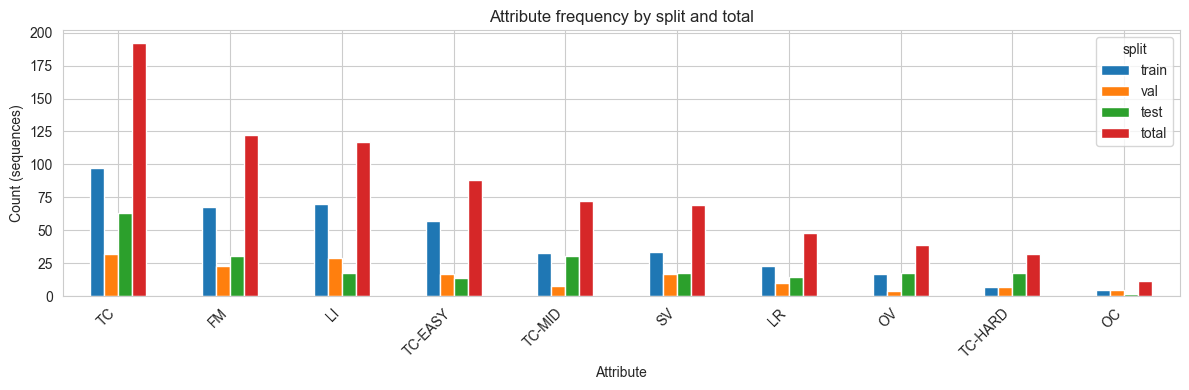

In [31]:
# Extract attributes at sequence-level (one row per sequence-attribute pair)
from itertools import chain

attr_rows = []
for split in SPLITS:
    for seq_id, attrs in attr_labels.get(split, {}).items():
        if isinstance(attrs, list):
            for attr in attrs:
                attr_rows.append({"split": split, "seq_id": seq_id, "attribute": attr})

attr_df = pd.DataFrame(attr_rows)
print("Sequence-attribute pairs:", len(attr_df))
print("Unique attributes:", attr_df["attribute"].nunique())

# Count attributes by split + total
attr_freq = (
    attr_df.groupby(["attribute", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SPLITS, fill_value=0)
    .astype(int)
    .copy()
 )
attr_freq["total"] = attr_freq.sum(axis=1)
attr_freq = attr_freq.sort_values("total", ascending=False)

print("\nAttribute frequency (sequence-level) by split and total:")
print(attr_freq)

ax = attr_freq[["train", "val", "test", "total"]].plot(kind="bar", figsize=(12, 4))
ax.set_title("Attribute frequency by split and total")
ax.set_xlabel("Attribute")
ax.set_ylabel("Count (sequences)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

TC (thermal challenge) is the dominant attribute, present in over 60% of sequences, followed by FM (fast motion) and LI (low illumination). This reflects the dataset's focus on thermally challenging conditions. Rare attributes OV (out-of-view) and OC (occlusion) are underrepresented.

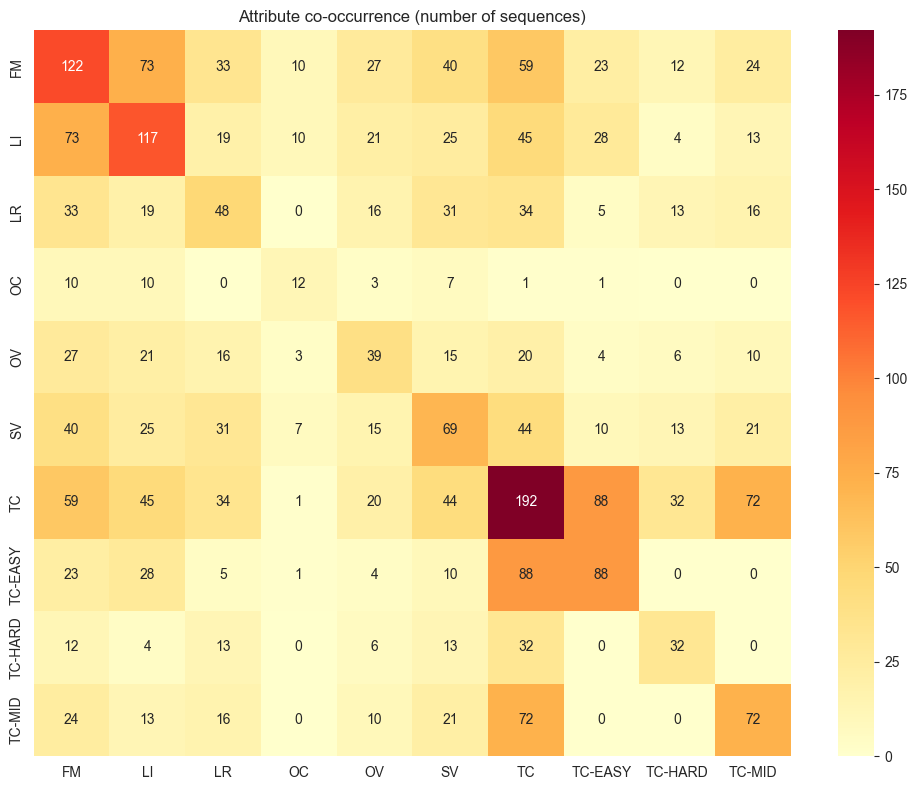

In [32]:
# Co-occurrence: for each pair of attributes, count sequences that have both
attr_list = sorted(attr_df["attribute"].unique())
n_a = len(attr_list)
cooc = np.zeros((n_a, n_a), dtype=int)

seq_attr_sets = []
for split in SPLITS:
    for attrs in attr_labels.get(split, {}).values():
        seq_attr_sets.append(set(attrs if isinstance(attrs, list) else []))

for attrs_set in seq_attr_sets:
    for i, a in enumerate(attr_list):
        for j, b in enumerate(attr_list):
            if a in attrs_set and b in attrs_set:
                cooc[i, j] += 1

cooc_df = pd.DataFrame(cooc, index=attr_list, columns=attr_list)
plt.figure(figsize=(10, 8))
sns.heatmap(cooc_df, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Attribute co-occurrence (number of sequences)")
plt.tight_layout()
plt.show()

TC is the most common attribute (192 sequences) and co-occurs broadly with all others. TC-EASY, TC-MID, and TC-HARD are mutually exclusive (off-diagonal zeros) and always appear with TC by construction. FM and LI co-occur frequently (73 sequences), suggesting low-light conditions often coincide with fast motion. OC is the rarest attribute and barely co-occurs with anything, representing an isolated and uncommon challenge.

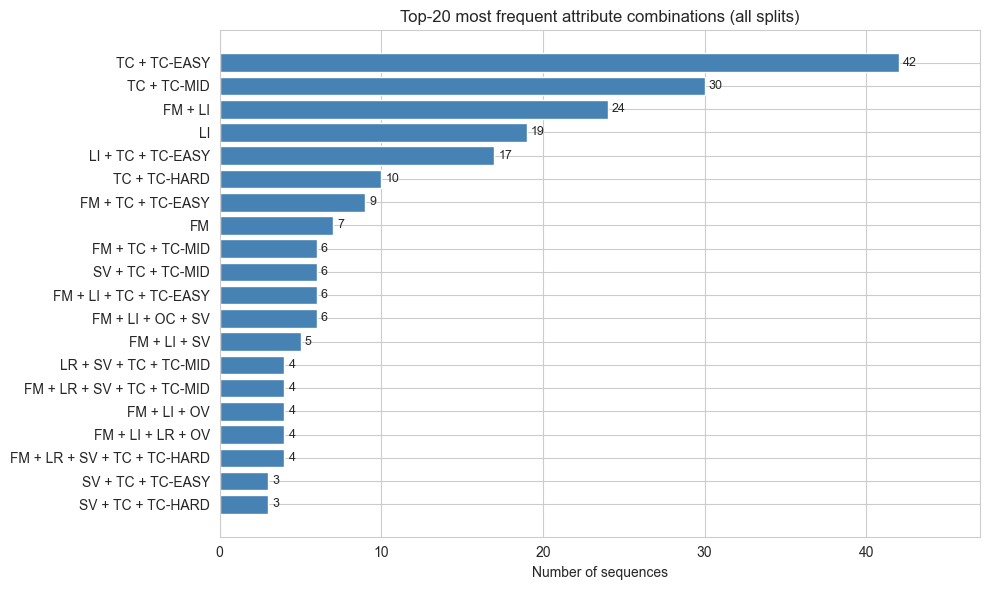


Total unique attribute combinations: 70

Top-20 combinations:
   42  {TC, TC-EASY}
   30  {TC, TC-MID}
   24  {FM, LI}
   19  {LI}
   17  {LI, TC, TC-EASY}
   10  {TC, TC-HARD}
    9  {FM, TC, TC-EASY}
    7  {FM}
    6  {FM, TC, TC-MID}
    6  {SV, TC, TC-MID}
    6  {FM, LI, TC, TC-EASY}
    6  {FM, LI, OC, SV}
    5  {FM, LI, SV}
    4  {LR, SV, TC, TC-MID}
    4  {FM, LR, SV, TC, TC-MID}
    4  {FM, LI, OV}
    4  {FM, LI, LR, OV}
    4  {FM, LR, SV, TC, TC-HARD}
    3  {SV, TC, TC-EASY}
    3  {SV, TC, TC-HARD}


In [33]:

# Frequent attribute combinations (itemset counting)
# Count every unique sorted combination of attributes across all sequences.
from collections import Counter

TOP_N = 20  # how many top combos to show

combo_counter = Counter()
for split in SPLITS:
    for attrs in attr_labels.get(split, {}).values():
        if isinstance(attrs, list) and len(attrs) > 0:
            key = tuple(sorted(set(attrs)))  # sorted, deduplicated
            combo_counter[key] += 1

top_combos = combo_counter.most_common(TOP_N)
combo_labels = [" + ".join(c) for c, _ in top_combos]
combo_counts = [cnt for _, cnt in top_combos]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(combo_labels[::-1], combo_counts[::-1], color="steelblue", edgecolor="white")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("Number of sequences")
ax.set_title(f"Top-{TOP_N} most frequent attribute combinations (all splits)")
ax.set_xlim(0, max(combo_counts) * 1.12)
plt.tight_layout()
plt.show()

print(f"\nTotal unique attribute combinations: {len(combo_counter)}")
print(f"\nTop-{TOP_N} combinations:")
for combo, cnt in top_combos:
    print(f"  {cnt:3d}  {{{', '.join(combo)}}}")


The dominant challenge is thermal alone: {TC, TC-EASY} and {TC, TC-MID} together account for 72 sequences with no other stressors. The next most common pattern introduces visual difficulty: {FM, LI} (24 sequences) represents fast motion in low light without thermal challenge. Sequences with 4–5 simultaneous attributes exist but are rare. With 70 unique combinations from 318 sequences, the dataset is diverse but long-tailed: a handful of combinations dominate training data while most are seen only 3–6 times.

---
## 5. RGB vs thermal data analysis

Comparing the visible and infrared modalities at frame and sequence level:

- **Cross-modal exist alignment**: per-frame agreement between visible and infrared exist labels
- **Attribute-linked modality degradation**: mean exist rate per attribute for visible vs infrared, compared against the dataset-wide baseline to identify which challenge types suppress each modality

Exist label agreement (visible vs infrared): 282354 / 296901 (95.10%)
  Visible=1, Infrared=0: 778
  Visible=0, Infrared=1: 13769

Per-split exist agreement:
       agree_%  V=1, IR=0  V=0, IR=1
split                               
train    95.60        202       6378
val      95.51        233       2551
test     93.93        343       4840


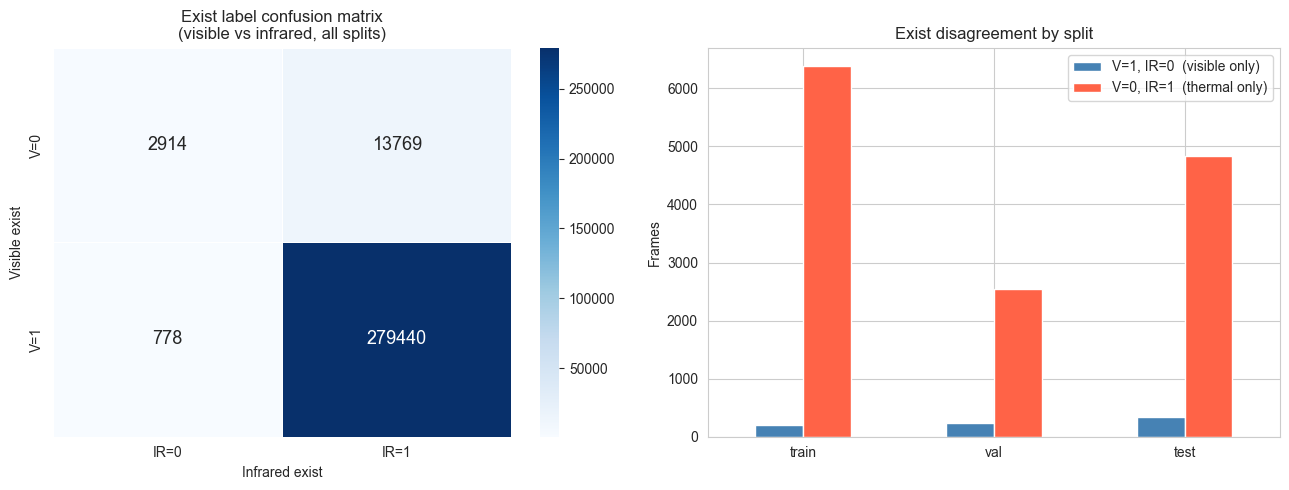

In [34]:
# Per-frame alignment: compare visible vs infrared exist for each (split, seq_id, frame_idx)
vis = df[df["modality"] == "visible"].set_index(["split", "seq_id", "frame_idx"])
inf = df[df["modality"] == "infrared"].set_index(["split", "seq_id", "frame_idx"])
common = vis.index.intersection(inf.index)
exist_vis = vis.loc[common, "exist"]
exist_inf = inf.loc[common, "exist"]

agree = (exist_vis == exist_inf).sum()
print(f"Exist label agreement (visible vs infrared): {agree} / {len(common)} ({100*agree/len(common):.2f}%)")
print(f"  Visible=1, Infrared=0: {((exist_vis==1) & (exist_inf==0)).sum()}")
print(f"  Visible=0, Infrared=1: {((exist_vis==0) & (exist_inf==1)).sum()}")

# --- 1: Confusion matrix ---
conf = pd.crosstab(exist_vis.rename("Visible"), exist_inf.rename("Infrared"))
conf.index   = [f"V={i}" for i in conf.index]
conf.columns = [f"IR={c}" for c in conf.columns]

# --- 2: Per-split disagreement ---
split_rows = []
for split in SPLITS:
    vis_s = df[(df["modality"] == "visible")  & (df["split"] == split)].set_index(["seq_id", "frame_idx"])["exist"]
    inf_s = df[(df["modality"] == "infrared") & (df["split"] == split)].set_index(["seq_id", "frame_idx"])["exist"]
    common_s = vis_s.index.intersection(inf_s.index)
    ev, ei = vis_s.loc[common_s], inf_s.loc[common_s]
    split_rows.append({
        "split":    split,
        "agree_%":  round(100 * (ev == ei).mean(), 2),
        "V=1, IR=0": int(((ev == 1) & (ei == 0)).sum()),
        "V=0, IR=1": int(((ev == 0) & (ei == 1)).sum()),
    })
agree_split_df = pd.DataFrame(split_rows).set_index("split")
print("\nPer-split exist agreement:")
print(agree_split_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(conf, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            ax=axes[0], annot_kws={"size": 13})
axes[0].set_title("Exist label confusion matrix\n(visible vs infrared, all splits)")
axes[0].set_ylabel("Visible exist")
axes[0].set_xlabel("Infrared exist")

agree_split_df[["V=1, IR=0", "V=0, IR=1"]].plot(
    kind="bar", ax=axes[1], color=["steelblue", "tomato"], edgecolor="white"
)
axes[1].set_title("Exist disagreement by split")
axes[1].set_xlabel("")
axes[1].set_ylabel("Frames")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["V=1, IR=0  (visible only)", "V=0, IR=1  (thermal only)"])
plt.tight_layout()
plt.show()


Both modalities agree on 95% of frames. When they disagree, infrared detects the drone while visible does not in 13,769 frames. Roughly 18× more often than the reverse (778 frames). This asymmetry is consistent across all splits. The 778 visible-only detections are likely edge cases where the drone is visually salient but thermally indistinct.

Baseline (all sequences) — visible: 0.9438, infrared: 0.9876

Mean exist rate by attribute and modality (sequences WITH the attribute):
attribute  n_seqs  vis_exist  ir_exist      gap
       FM     122   0.953427  0.982318 0.028891
       LI     117   0.929936  0.985915 0.055979
       LR      48   0.916471  0.984408 0.067937
       OC      12   0.855929  0.921069 0.065140
       OV      39   0.819436  0.917555 0.098119
       SV      69   0.912663  0.962140 0.049477
       TC     192   0.942201  0.994521 0.052320
  TC-EASY      88   0.953213  0.998200 0.044987
  TC-HARD      32   0.922974  0.984380 0.061406
   TC-MID      72   0.937850  0.994734 0.056884


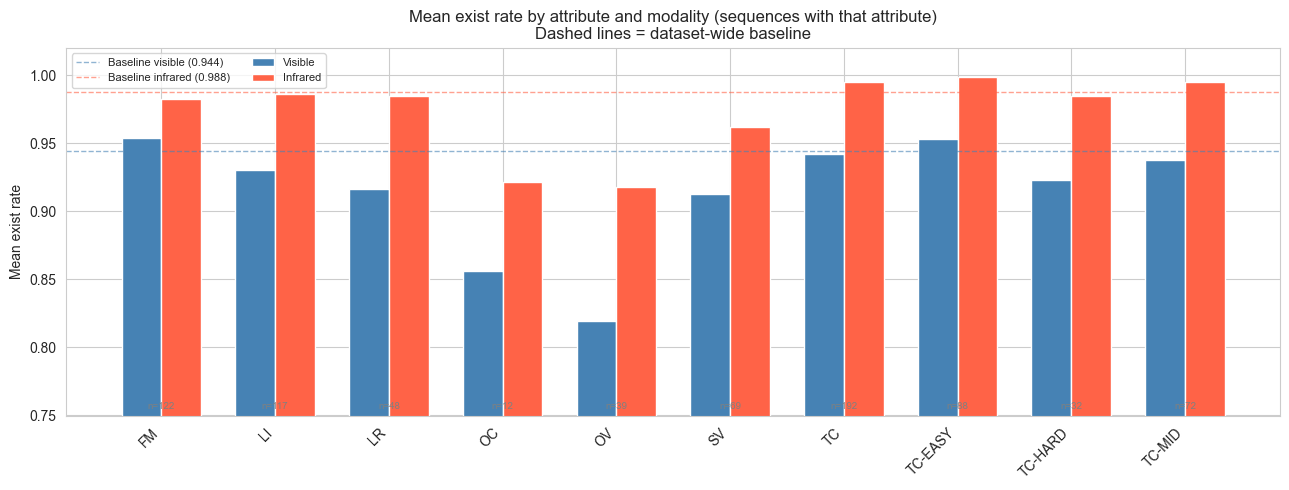

In [35]:
# Attribute-linked modality degradation — generalized over all attributes.
# For each attribute: mean exist rate (visible vs infrared) for sequences WITH it.
# Baseline: overall mean exist across all sequences gives context.

# Build seq_id → attribute set once (dict map is vectorised in pandas)
seq_attr_map = {
    sid: set(attrs) if isinstance(attrs, list) else set()
    for split in SPLITS
    for sid, attrs in attr_labels.get(split, {}).items()
}
all_attrs = sorted({a for aset in seq_attr_map.values() for a in aset})

# Baseline: exist rates over ALL sequences (no attribute filter)
base_vis = df[df["modality"] == "visible"]["exist"].mean()
base_ir  = df[df["modality"] == "infrared"]["exist"].mean()
print(f"Baseline (all sequences) — visible: {base_vis:.4f}, infrared: {base_ir:.4f}")

# Per-attribute stats
records = []
for attr in all_attrs:
    seq_has = {sid: (attr in aset) for sid, aset in seq_attr_map.items()}
    mask = df["seq_id"].map(seq_has)
    grp  = df[mask]
    n_seqs = grp["seq_id"].nunique()
    records.append({
        "attribute": attr,
        "n_seqs":    n_seqs,
        "vis_exist": grp[grp["modality"] == "visible"]["exist"].mean(),
        "ir_exist":  grp[grp["modality"] == "infrared"]["exist"].mean(),
    })

deg_df = pd.DataFrame(records).sort_values("attribute").reset_index(drop=True)
deg_df["gap"] = deg_df["ir_exist"] - deg_df["vis_exist"]

print("\nMean exist rate by attribute and modality (sequences WITH the attribute):")
print(deg_df.to_string(index=False))

# --- Plot ---
x = np.arange(len(deg_df))
width = 0.35
ymin = deg_df[["vis_exist", "ir_exist"]].min().min() - 0.07

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - width / 2, deg_df["vis_exist"], width, label="Visible",  color="steelblue")
ax.bar(x + width / 2, deg_df["ir_exist"],  width, label="Infrared", color="tomato")
ax.axhline(base_vis, color="steelblue", linewidth=1, linestyle="--", alpha=0.6, label=f"Baseline visible ({base_vis:.3f})")
ax.axhline(base_ir,  color="tomato",    linewidth=1, linestyle="--", alpha=0.6, label=f"Baseline infrared ({base_ir:.3f})")
for i, row in deg_df.iterrows():
    ax.text(i, ymin + 0.005, f"n={int(row['n_seqs'])}", ha="center", fontsize=7, color="gray")
ax.set_xticks(x)
ax.set_xticklabels(deg_df["attribute"], rotation=45, ha="right")
ax.set_ylim(ymin, 1.02)
ax.set_ylabel("Mean exist rate")
ax.set_title("Mean exist rate by attribute and modality (sequences with that attribute)\nDashed lines = dataset-wide baseline")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


Infrared outperforms visible for every attribute without exception. The largest visible degradation occurs under OV (out-of-view, 0.819) and OC (occlusion, 0.856), both well below the visible baseline of 0.944. LR (low resolution) and LI (low illumination) hurt visible moderately but leave infrared near baseline. TC sequences show almost no infrared degradation, confirming thermal challenge affects signal degradation rather than causing total target loss. The gap between modalities is largest for OV (0.098).

---
## 6. Data cleaning

Consistency between *exist* and bounding boxes; invalid or zero-area boxes.

In [36]:
# Inconsistencies: exist=1 but no valid bbox vs exist=0 but valid bbox
df["has_valid_bbox"] = df["w"].notna() & (df["w"] > 0) & (df["h"] > 0)
exist1_no_bbox  = ((df["exist"] == 1) & (~df["has_valid_bbox"])).sum()
exist0_has_bbox = ((df["exist"] == 0) & (  df["has_valid_bbox"])).sum()
total = len(df)

print(f"Frames with exist=1 but no valid bbox : {exist1_no_bbox}  ({100*exist1_no_bbox/total:.3f}% of all frames)")
print(f"Frames with exist=0 but valid bbox    : {exist0_has_bbox}  ({100*exist0_has_bbox/total:.3f}% of all frames)")
print(f"Total inconsistent frames             : {exist1_no_bbox + exist0_has_bbox}  ({100*(exist1_no_bbox+exist0_has_bbox)/total:.3f}%)")

Frames with exist=1 but no valid bbox : 445  (0.075% of all frames)
Frames with exist=0 but valid bbox    : 475  (0.080% of all frames)
Total inconsistent frames             : 920  (0.155%)


The 0.15% inconsistency rate is negligible and no data needs to be removed. However, the 445 frames with exist=1 but no valid bounding box require careful handling during training: the bounding box regression loss should be masked to frames where both exist=1 AND a valid bbox is present, while the classification (exist) loss is computed on all frames. This prevents the model from being penalized for correctly predicting presence when no ground-truth box is available.

---
## 7. Conclusions

This EDA explored the Anti-UAV-RGBT dataset across six dimensions. The main findings are summarised below.

**Dataset structure.**
318 sequences (~297k frames per modality) split across train/val/test. Sequence lengths are tightly clustered around 930–940 frames, with a small tail of very short sequences.

**Target analysis.**
The dataset is heavily presence-dominated: 93–95% of visible frames and 98–99% of infrared frames have the drone present (`exist=1`). Absence events are rare and typically short, but when they do occur the drone re-appears and disappears multiple times within a sequence.

**Bounding box analysis.**
Drone boxes are small relative to frame size (median normalised scale below 0.1). The position heatmaps show a centre bias across all three splits, suggesting sequences are typically captured with the drone kept near the middle of the frame. The aspect ratio distribution is slightly wider than 1.

**Attribute analysis.**
TC is the most frequent attribute, present in 192 of 318 sequences, followed by FM (122) and LI (117). Thermal challenge levels (TC-EASY / TC-MID / TC-HARD) are mutually exclusive by construction and always appear together with the parent label TC.

**RGB vs thermal.**
Thermal is the more robust modality: when the two modalities disagree on `exist`, infrared detects the drone and visible does not ~17.7× more often than the reverse. Infrared consistently outperforms visible across every attribute. The largest degradation occurs in OV and OC sequences, where both modalities drop well below their baselines. Attributes that are physically specific to one modality (LI for visible, TC for infrared) behave differently: LI pushes the visible exist rate below baseline as expected, whereas TC sequences show almost no infrared degradation. An explanation for this could be that TC reduces signal contrast rather than causing total target loss.

**Data quality.**
920 frames (0.15%) show exist/bbox inconsistencies -> negligible at this scale. No rows need to be removed. The inconsistencies are handled at loss computation time by masking the bbox regression loss to frames where `exist=1 AND has_valid_bbox`, while using the `exist` label on all frames for the classification loss.
